# Consigna 6: Análisis de Sensitividad en SymPy y Validación de $\pm 1\%$
**Trabajo Práctico de Filtros — Síntesis de Redes Activas (FCEFyN - UNC)**
* **Filtro Implementado:** Pasabajos Butterworth de 3.er Orden ($N = 3$, $W_n = 8900\text{ rad/s}$)

---
La sensitividad relativa normalizada de un parámetro $y$ respecto de un elemento independiente $x$ se define como:
$$S_x^y = \frac{\partial y}{\partial x} \cdot \frac{x}{y}$$
* **Sección de 2.do orden (Sallen-Key):** Se calculan en SymPy: las expresiones analíticas de $S_x^{\omega_{02}}$ y $S_x^Q$ para $x \in \{R_1, R_2, C_1, C_2\}$ **antes de imponer igualdades entre componentes** ($R_1 \neq R_2$, $C_1 \neq C_2$).
* **Sección de 1.er orden:** Al poseer un polo real único en $s = -\omega_{01}$, carece de par complejo conjugado y el factor de calidad $Q$ no constituye un parámetro aplicable. Se estudia la sensitividad de su parámetro característico pertinente: $\omega_{01} = (R_3 C_3)^{-1}$.
* **Validación numérica:** Se perturba cada componente en $+1\%$ y $-1\%$ alrededor del punto comercial nominal ($R_3 = 11\text{ k}\Omega$, $C_3 = 10\text{ nF}$, $R_1 = R_2 = 12\text{ k}\Omega$, $C_1 = 4.7\text{ nF}$, $C_2 = 18\text{ nF}$) y se contrasta la variación exacta frente a la predicción lineal $S_x^y \cdot (\pm 1\%)$.

In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Math

sp.init_printing(use_latex='mathjax')
plt.rcParams.update({
    'figure.dpi': 130,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'font.size': 10
})

# Definición de variables simbólicas independientes y extracción desde ecuaciones nodales
s = sp.symbols('s')
Vi, Vp1, Vo1, Va, Vb, Vo = sp.symbols('Vi Vp1 Vo1 Va Vb Vo')
R1, R2, C1, C2, R3, C3 = sp.symbols('R1 R2 C1 C2 R3 C3', positive=True, real=True)
K1, K2 = sp.symbols('K1 K2', positive=True, real=True)

def normalizar(H):
    num, den = sp.fraction(sp.together(H))
    poly_den = sp.Poly(den, s)
    lc = poly_den.LC()
    num_norm = sp.simplify(num / lc)
    den_norm = sp.collect(sp.expand(den / lc), s)
    return num_norm, den_norm

# Sección 1 (1.er Orden)
eq1_s1 = sp.Eq((Vp1 - Vi)/R3 + s*C3*Vp1, 0)
eq2_s1 = sp.Eq(Vo1, K1 * Vp1)
sol_s1 = sp.solve([eq1_s1, eq2_s1], (Vp1, Vo1))
_, den1 = normalizar(sp.simplify(sol_s1[Vo1] / Vi))

# Sección 2 (2.do Orden Sallen-Key)
eq1_s2 = sp.Eq((Va - Vo1)/R1 + (Va - Vb)/R2 + s*C2*(Va - Vo), 0)
eq2_s2 = sp.Eq((Vb - Va)/R2 + s*C1*Vb, 0)
eq3_s2 = sp.Eq(Vo, K2 * Vb)
sol_s2 = sp.solve([eq1_s2, eq2_s2, eq3_s2], (Va, Vb, Vo))
_, den2 = normalizar(sp.simplify(sol_s2[Vo] / Vo1))

# Parámetros simbólicos (ANTES de imponer R1 = R2)
w01_sym  = sp.simplify(den1.coeff(s, 0))
a1_sym   = sp.simplify(den2.coeff(s, 1))   # = w02 / Q
a0_sym   = sp.simplify(den2.coeff(s, 0))   # = w02^2
w02_sym  = sp.powsimp(sp.sqrt(a0_sym), force=True)
Q_sym    = sp.simplify(sp.powsimp(w02_sym / a1_sym, force=True))
Q_k1_sym = sp.simplify(Q_sym.subs(K2, 1))

# Valores comerciales nominales (Punto 5, Wn = 8900 rad/s)
nom = {
    R3: 11e3, C3: 10e-9,
    R1: 12e3, R2: 12e3,
    C1: 4.7e-9, C2: 18e-9,
    K1: 1, K2: 1
}

display(Math(r"\omega_{01} = " + sp.latex(w01_sym) + r", \qquad \omega_{02} = " + sp.latex(w02_sym)))
display(Math(r"Q_{\text{general}} = " + sp.latex(Q_sym) + r", \qquad \left. Q \right|_{K_2=1} = " + sp.latex(Q_k1_sym)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:14: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_822/3585440586.py:14: SyntaxWarning: invalid escape sequence '\l'
  f"\left. S_{{{sp.latex(comp)}}}^Q \right|_{{K_2=1}} = {sp.latex(SQ_k1)}, \\qquad "


=== EXPRESIONES SIMBÓLICAS DE SENSIBILIDAD (ANTES DE IMPONER R1 = R2) ===


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

,Sección,Componente x,S_x^{w02},S_x^Q (K2 libre),"S_x^Q (K2=1, R1!=R2)",Valor Nominal (w02),Valor Nominal (Q)
0,2.do Orden (Sallen-Key),R1,-1/2,(-C1*R1 + C1*R2 + C2*K2*R1 - C2*R1)/(2*(C1*R1 ...,(-R1 + R2)/(2*(R1 + R2)),-0.5,0.0
1,2.do Orden (Sallen-Key),R2,-1/2,(C1*R1 - C1*R2 - C2*R1*(K2 - 1))/(2*(C1*R1 + C...,(R1 - R2)/(2*(R1 + R2)),-0.5,0.0
2,2.do Orden (Sallen-Key),C1,-1/2,(-C1*R1 - C1*R2 - C2*K2*R1 + C2*R1)/(2*(C1*R1 ...,-1/2,-0.5,-0.5
3,2.do Orden (Sallen-Key),C2,-1/2,(C1*R1 + C1*R2 + C2*R1*(K2 - 1))/(2*(C1*R1 + C...,1/2,-0.5,0.5
4,1.er Orden (RC + Buffer),R3,S_w01 = -1,No aplica (polo real),No aplica (polo real),-1.0,NaN
5,1.er Orden (RC + Buffer),C3,S_w01 = -1,No aplica (polo real),No aplica (polo real),-1.0,NaN



=== TABLA DE VALIDACIÓN CON PERTURBACIONES FINITAS DE +-1% ===


,Parámetro,Valor Nominal y0,Comp. x,S_x^y Analítica,Predicción Lineal (+1%) [%],Exacto +1% [%],Exacto -1% [%],S_x^y Dif. Centrada,Discrepancia |S - S_num|
0,w02 [rad/s],9060.11213,R1,-0.5,-0.5,-0.4963,0.5038,-0.5000,0.000031
1,w02 [rad/s],9060.11213,R2,-0.5,-0.5,-0.4963,0.5038,-0.5000,0.000031
2,w02 [rad/s],9060.11213,C1,-0.5,-0.5,-0.4963,0.5038,-0.5000,0.000031
3,w02 [rad/s],9060.11213,C2,-0.5,-0.5,-0.4963,0.5038,-0.5000,0.000031
4,Q,0.97849,R1,0.0,0.0,-0.0012,-0.0013,0.0000,0.000013
5,Q,0.97849,R2,0.0,0.0,-0.0012,-0.0013,0.0000,0.000013
6,Q,0.97849,C1,-0.5,-0.5,-0.4963,0.5038,-0.5000,0.000031
7,Q,0.97849,C2,0.5,0.5,0.4988,-0.5013,0.5000,0.000006
8,w01 [rad/s],9090.90909,R3,-1.0,-1.0,-0.9901,1.0101,-1.0001,0.000100
9,w01 [rad/s],9090.90909,C3,-1.0,-1.0,-0.9901,1.0101,-1.0001,0.000100


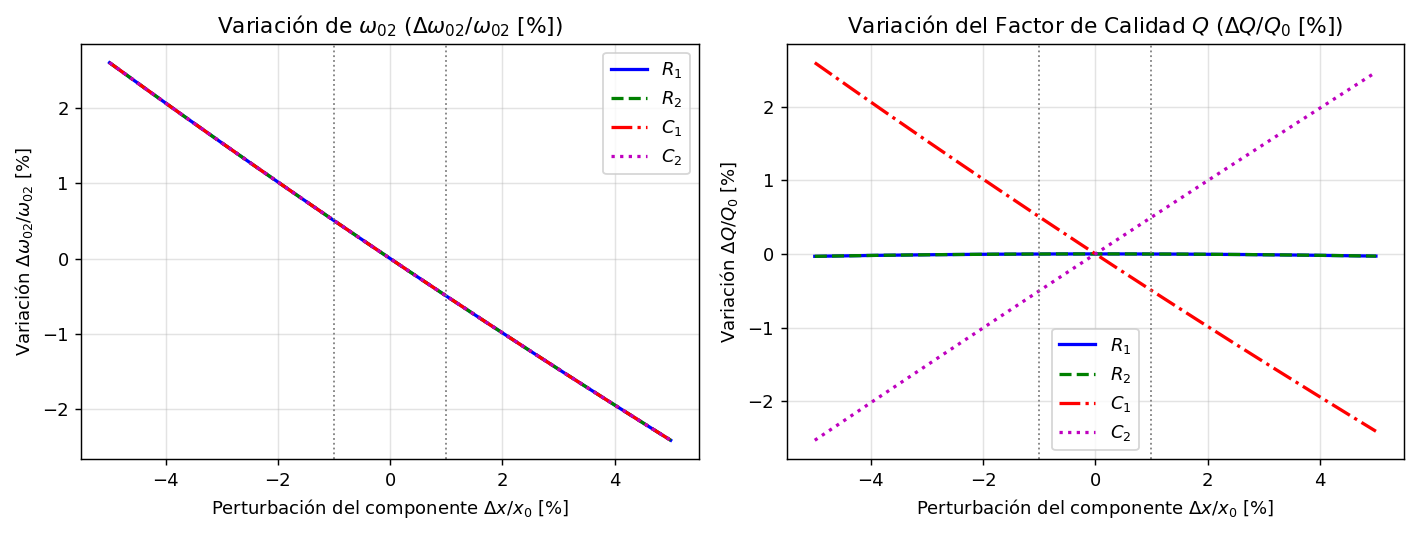

In [4]:
def sensibilidad(y, x):
    """Calcula la sensibilidad normalizada S_x^y = (dy/dx)*(x/y) de forma simbólica."""
    return sp.simplify(sp.diff(y, x) * x / y)

# 1. Cálculo simbólico ANTES de imponer R1 = R2
print("=== EXPRESIONES SIMBÓLICAS DE SENSIBILIDAD (ANTES DE IMPONER R1 = R2) ===")
filas_sens = []
for comp in [R1, R2, C1, C2]:
    Sw2 = sensibilidad(w02_sym, comp)
    SQ_gen = sensibilidad(Q_sym, comp)
    SQ_k1  = sensibilidad(Q_k1_sym, comp)
    display(Math(
        f"S_{{{sp.latex(comp)}}}^{{\\omega_{{02}}}} = {sp.latex(Sw2)}, \\qquad "
        f"\left. S_{{{sp.latex(comp)}}}^Q \right|_{{K_2=1}} = {sp.latex(SQ_k1)}, \\qquad "
        f"S_{{{sp.latex(comp)}}}^Q = {sp.latex(SQ_gen)}"
    ))
    filas_sens.append({
        "Sección": "2.do Orden (Sallen-Key)",
        "Componente x": str(comp),
        "S_x^{w02}": str(Sw2),
        "S_x^Q (K2 libre)": str(SQ_gen),
        "S_x^Q (K2=1, R1!=R2)": str(SQ_k1),
        "Valor Nominal (w02)": float(Sw2.subs(nom)),
        "Valor Nominal (Q)": float(SQ_k1.subs(nom))
    })

for comp in [R3, C3]:
    Sw1 = sensibilidad(w01_sym, comp)
    display(Math(f"S_{{{sp.latex(comp)}}}^{{\\omega_{{01}}}} = {sp.latex(Sw1)}"))
    filas_sens.append({
        "Sección": "1.er Orden (RC + Buffer)",
        "Componente x": str(comp),
        "S_x^{w02}": f"S_w01 = {Sw1}",
        "S_x^Q (K2 libre)": "No aplica (polo real)",
        "S_x^Q (K2=1, R1!=R2)": "No aplica (polo real)",
        "Valor Nominal (w02)": float(Sw1.subs(nom)),
        "Valor Nominal (Q)": np.nan
    })

df_sens = pd.DataFrame(filas_sens)
display(df_sens)

# 2. Validación mediante perturbaciones finitas individuales de +1% y -1%
filas_val = []
for nombre_param, expr_sym, lista_comp in [
    ("w02 [rad/s]", w02_sym, [R1, R2, C1, C2]),
    ("Q",           Q_k1_sym, [R1, R2, C1, C2]),
    ("w01 [rad/s]", w01_sym, [R3, C3])
]:
    y0 = float(expr_sym.subs(nom))
    for x in lista_comp:
        S_teo = float(sensibilidad(expr_sym, x).subs(nom))
        p_pos = nom.copy(); p_pos[x] = nom[x] * 1.01
        p_neg = nom.copy(); p_neg[x] = nom[x] * 0.99
        y_pos = float(expr_sym.subs(p_pos))
        y_neg = float(expr_sym.subs(p_neg))
        dy_pos_pct = (y_pos - y0) / y0 * 100.0
        dy_neg_pct = (y_neg - y0) / y0 * 100.0
        S_cent = (y_pos - y_neg) / (2.0 * 0.01 * y0)
        filas_val.append({
            "Parámetro": nombre_param,
            "Valor Nominal y0": round(y0, 5),
            "Comp. x": str(x),
            "S_x^y Analítica": round(S_teo, 4),
            "Predicción Lineal (+1%) [%]": round(S_teo * 1.0, 4),
            "Exacto +1% [%]": round(dy_pos_pct, 4),
            "Exacto -1% [%]": round(dy_neg_pct, 4),
            "S_x^y Dif. Centrada": round(S_cent, 4),
            "Discrepancia |S - S_num|": round(abs(S_teo - S_cent), 6)
        })

df_val = pd.DataFrame(filas_val)
print("\n=== TABLA DE VALIDACIÓN CON PERTURBACIONES FINITAS DE +-1% ===")
display(df_val)

# 3. Gráfico de sensibilidad frente a variaciones de -5% a +5% (sensibilidad_1pct.png)
deltas = np.linspace(-0.05, 0.05, 201)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
w0_base = float(w02_sym.subs(nom))
q0_base = float(Q_k1_sym.subs(nom))

for comp, estilo, etiqueta in [(R1, 'b-', '$R_1$'), (R2, 'g--', '$R_2$'), (C1, 'r-.', '$C_1$'), (C2, 'm:', '$C_2$')]:
    w_curve, q_curve = [], []
    for d in deltas:
        p = nom.copy(); p[comp] = nom[comp] * (1.0 + d)
        w_curve.append((float(w02_sym.subs(p)) - w0_base) / w0_base * 100.0)
        q_curve.append((float(Q_k1_sym.subs(p)) - q0_base) / q0_base * 100.0)
    ax1.plot(deltas * 100, w_curve, estilo, lw=1.8, label=etiqueta)
    ax2.plot(deltas * 100, q_curve, estilo, lw=1.8, label=etiqueta)

ax1.axvline(1.0, color='gray', ls=':', lw=1); ax1.axvline(-1.0, color='gray', ls=':', lw=1)
ax1.set_title(r'Variación de $\omega_{02}$ ($\Delta \omega_{02} / \omega_{02}$ [%])')
ax1.set_xlabel(r'Perturbación del componente $\Delta x / x_0$ [%]')
ax1.set_ylabel(r'Variación $\Delta \omega_{02} / \omega_{02}$ [%]')
ax1.legend()

ax2.axvline(1.0, color='gray', ls=':', lw=1); ax2.axvline(-1.0, color='gray', ls=':', lw=1)
ax2.set_title(r'Variación del Factor de Calidad $Q$ ($\Delta Q / Q_0$ [%])')
ax2.set_xlabel(r'Perturbación del componente $\Delta x / x_0$ [%]')
ax2.set_ylabel(r'Variación $\Delta Q / Q_0$ [%]')
ax2.legend()

plt.tight_layout()
plt.savefig('sensibilidad_1pct.png', dpi=200)
plt.show()